# Experimentation
---
In this notebook, we experiment with different functino settings, base data, files, concepts and visualisations. The goal is to find the best way to convey the findings of our research, both in terms of visualisation, but also in terms of metrics which are used for the communication.

In [37]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from cycler import cycler
from kiln_ring_analysis_function import kiln_ring_analysis, DEFAULTS as ANALYSIS_DEFAULTS
from plot_kiln_rings_function import plot_kiln_rings, DEFAULTS as PLOT_DEFAULTS
from helpers import save_fig


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


For a constant look, we define a colour scheme to be used for all graphs:

In [78]:
COLSCHEME = {
       "ember":  ["#FDBE85", "#F68C3A", "#D9541A"],
       "forest": ["#A8DDB5", "#4DAF6E", "#23794A"],
       "smoke":  ["#A6CEE3", "#4A90C8", "#2563A0"]
       }

plt.rcParams["axes.prop_cycle"] = cycler(color=[COLSCHEME["smoke"][2], COLSCHEME["ember"][2],
                                                COLSCHEME["forest"][2], COLSCHEME["smoke"][1],
                                                COLSCHEME["ember"][1], COLSCHEME["forest"][1]])

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "pdf.fonttype": 42,
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

***
## Display raw data
In this chapter we will start with 16 rays, 1m sample intervals and 6m ring intervals (up to 24m). The samples are not weighted.  

The analysis results are saved in: `new testfolder/results/merged_dem_rays16_step1_ring6x4`

### Run analysis

In [39]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24)],
    "n_rays": 16,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

samples = pd.read_csv("results/merged_dem_rays16_step1_ring6x4/merged_dem_samples.csv")
rings = [(0, 6), (6, 12), (12, 18), (18, 24)]

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          16 (every 22.5°), sample every 1 m up to 24 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 96 samples
       6-12    m: 96 samples
      12-18    m: 96 samples
      18-24    m: 96 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m
count   79.00   79.00    79.00    79.00
median   6.20    5.93     6.14     6.06
mean     6.73    6.45     6.39     6.53
std      3.88    3.55     3.50     3.37
min      0.00    0.00     0.00     0.19
25%      4.66    4.60     4.23     4.79
50%      6.20    5.93     6.14     6.06
75%      8.54    8.56     7.47     7.86
max     19.02   16.17    17.76    17.15

Rings left empty (too little valid data):
   mean_0_6: kilns [12]
   mean_6_12: kiln

### Plot function
Here, we define a function for plotting the raw outpur of the analysis. It plots each ray of each kiln. The function includes the possibility to smooth the output of each ray with a moving window. This is done to reduce the impact that noise has on the visualisation, hiding the trends we are looking for.

In [71]:
def plot_raw_rays(samples: pd.DataFrame, rings: list, window_size=1, l_alpha=0.1, st_dev=False, color=COLSCHEME, ctrl_samples=None):
    samples = samples.sort_values(["kiln_id", "ray", "distance"])
    samples["smooth"] = (samples.groupby(["kiln_id", "ray"])["value"].transform(lambda v: v.rolling(window_size, center=True, min_periods=1).mean()))

    def smooth(s):
        s = s.sort_values(["kiln_id", "ray", "distance"]).copy()
        s["smooth"] = s.groupby(["kiln_id", "ray"])["value"].transform(
            lambda v: v.rolling(window_size, center=True, min_periods=1).mean())
        return s

    samples = smooth(samples)
    fig, ax = plt.subplots(figsize=(6.3,3))

    # all lines
    for _, line in samples.groupby(["kiln_id", "ray"]):
        ax.plot(line["distance"], line["smooth"], color=color["forest"][1], alpha=l_alpha, lw=0.8)

    # mean ± 1 SD per distance, for the kilns and (optionally) the controls
    groups = [("Charcoal mounds", samples, color["ember"])]
    if ctrl_samples is not None:
        groups.append(("Controls", smooth(ctrl_samples), color["smoke"]))
    for label, s, c in groups:
        per_dist = s.groupby("distance")["smooth"]
        m, sd = per_dist.mean(), per_dist.std()
        ax.plot(m.index, m + sd, color=c[2], lw=0.8, ls="--", label=f"{label}: mean ± 1 SD")
        ax.plot(m.index, m - sd, color=c[2], lw=0.8, ls="--")
        ax.plot(m.index, m, color=c[2], lw=1.5, label=f"{label}: mean")

    # ring interval boundaries
    for _, outer in rings[:-1]:
        ax.axvline(outer, color="black", lw=0.6, ls=":", alpha=0.6)

    ax.set_xlim(1,rings[-1][-1])
    ax.set_ylim(0, max(samples["smooth"])+2)
    ax.set_xlabel("Distance from kiln (m)")
    if window_size == 1:
        ax.set_ylabel(f"Canopy height (m)")
    else:
        ax.set_ylabel(f"Smoothed canopy height (m) (window={window_size})")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig

### Plotting
We can now play with the plotting settings.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


[PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/ray_profiles_raw_with_control_sd.png'),
 PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/ray_profiles_raw_with_control_sd.pdf')]

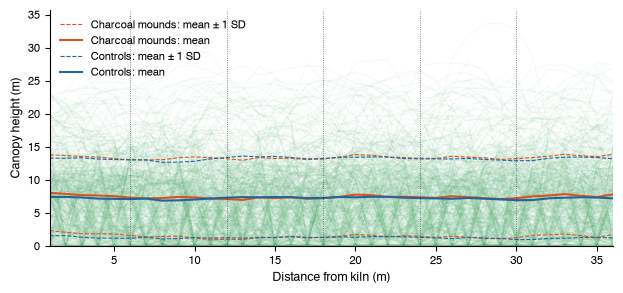

In [73]:
kiln_samples = pd.read_csv("results/merged_dem_rays8_step1_ring6x6_reduced/merged_dem_reduced_samples.csv")
ctrl_samples = pd.read_csv("results/merged_dem_rays8_step1_ring6x6_controls/merged_dem_controls_samples.csv")

fig = plot_raw_rays(kiln_samples, rings, window_size=1, l_alpha=0.06, ctrl_samples=ctrl_samples)
save_fig("ray_profiles_raw_with_control_sd")

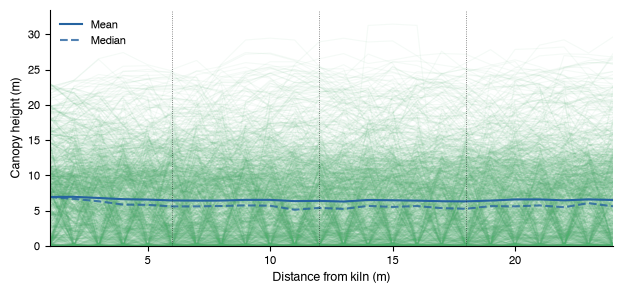

In [45]:
res_1 = plot_raw_rays(samples=samples, rings=rings, window_size=1, l_alpha=0.06)
res_1.savefig("results/merged_dem_rays16_step1_ring6x4/ray_profiles_raw.png", dpi=400)

This plot is very messy. Mainly due to the zig zag pattern at the bottom which is a result of pixels with value 0 representing the floor. There are a lot of rays that have floor pixels in the so this zig zag pattern cannot be avoided when plotting the raw pixel data.  

What can be seen is that on the very left, rays share pixel values due to the number of rays and the liimited number of pixels for small radii. This results in these few darker lines, indicating shared values. Once the radius is large enough that each ray has its own pixels, such artefacts disappear.  

**Floating average**  

What we can do is calculate a floating average for each pixel with a given window size. Let's try it with window size = 3 (i.e. it looks one pixel to the left and one to the right)

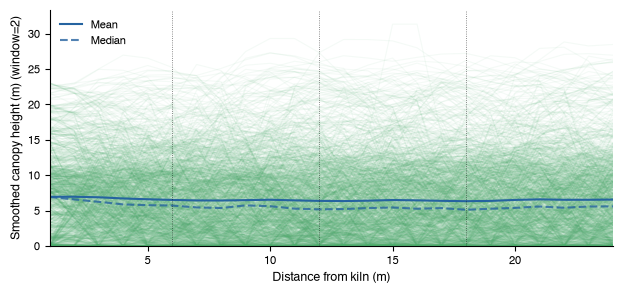

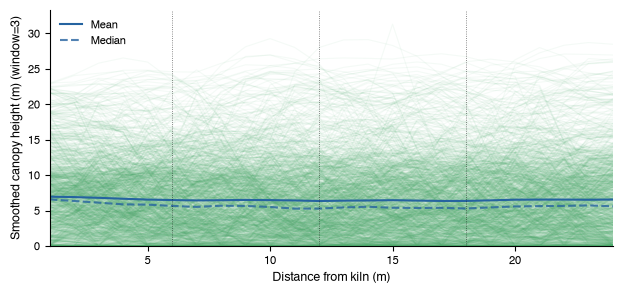

In [46]:
res_2 = plot_raw_rays(samples=samples, rings=rings, window_size=2, l_alpha=0.06)
res_3 = plot_raw_rays(samples=samples, rings=rings, window_size=3, l_alpha=0.06)

I don't know, whether these last 3 graphs are suitable for the report since the idea of this kind of graph is to truly show the data and how it looks like. The zig zag is not an artefact, it's part of the data. And the median and mean lines can still be interpreted well.

## 8 rings of 6m with 8 rays

In [47]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36), (36, 42), (42, 48)],
    "n_rays": 8,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

samples = pd.read_csv("results/merged_dem_rays8_step1_ring6x8/merged_dem_samples.csv")
rings = [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36), (36, 42), (42, 48)]

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          8 (every 45°), sample every 1 m up to 48 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples
      36-42    m: 48 samples
      42-48    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m  36-42 m  42-48 m
count   79.00   79.00    79.00    79.00    79.00    77.00    79.00    79.00
median   6.11    5.52     5.73     6.14     5.93     6.03     6.35     6.05
mean     6.74    6.40     6.40     6.50     6.46     6.77     6.83     6.45
std      3.87    3.62     3.69     3.58     3.20     3.47     3.47  

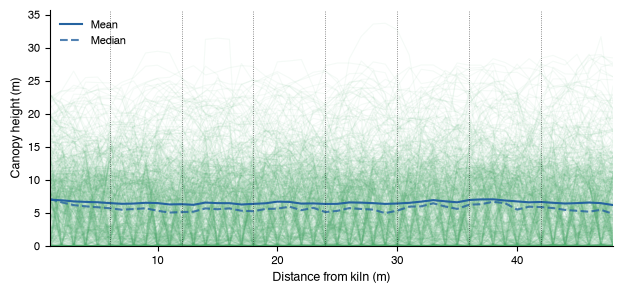

In [48]:
res_1 = plot_raw_rays(samples=samples, rings=rings, window_size=1, l_alpha=0.06)
res_1.savefig("results/merged_dem_rays8_step1_ring6x8/ray_profiles_raw.png", dpi=400)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          8 (every 45°), sample every 1 m up to 36 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m
count   79.00   79.00    79.00    79.00    79.00    77.00
median   6.11    5.52     5.73     6.14     5.93     6.03
mean     6.74    6.40     6.40     6.50     6.46     6.77
std      3.87    3.62     3.69     3.58     3.20     3.47
min      0.00    0.00     0.00     0.00     0.64     0.62
25%      4.70    4.61     4.13     4.46     4.67     4.68
50%      6.11    5.52   

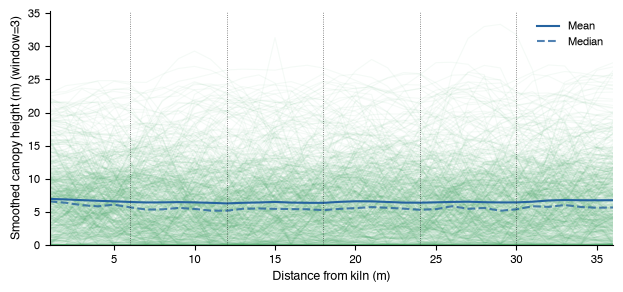

In [49]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)],
    "n_rays": 8,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

samples = pd.read_csv("results/merged_dem_rays8_step1_ring6x6/merged_dem_samples.csv")
rings = [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)]

res_1 = plot_raw_rays(samples=samples, rings=rings, window_size=3, l_alpha=0.06)
res_1.savefig("results/merged_dem_rays8_step1_ring6x6/ray_profiles_raw2.png", dpi=400)

## Analysis of reduced kohlmeiler set

In [50]:
rings = [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)]
params = {
    "gpkg": "kohlmeiler_2056_reduced.gpkg",
    "tif": "merged_dem.tif",
    "rings": rings,
    "n_rays": 8,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

samples = pd.read_csv("results/merged_dem_rays8_step1_ring6x6_reduced/merged_dem_reduced_samples.csv")

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         60 from kohlmeiler_2056_reduced.gpkg
Rays:          8 (every 45°), sample every 1 m up to 36 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m
count   60.00   60.00    60.00    60.00    60.00    60.00
median   6.74    5.97     6.21     6.58     6.19     6.44
mean     7.69    7.25     7.22     7.52     7.29     7.63
std      3.49    3.10     3.33     3.21     3.05     3.32
min      3.22    2.44     2.35     3.14     2.90     3.63
25%      5.31    5.28     5.17     5.37     5.39     5.34
50%      6.74   

## Analysis of control points
Having the numbers of the charcoal mounds' analyss is a first step, but it doesn't help us much if we cannot compare them to something. Idea of comparing the different distances is valid and to some extent ok, but due to spatial autocorrelation and other covariance problems, the inner rings pose a problem which cannot be solved by weighing the samples for example.  
That's where control points come to play. Ideally, these are three points assigned to each charcoal mound. These points lie within its vicinity and should represent the environment of the charcoal mound as good as possible. How this generation was done is explained in `control_points.ipynb`.  

In [51]:
params = {
    "gpkg": "controls_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)],
    "n_rays": 8,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

samples = pd.read_csv("results/merged_dem_rays8_step1_ring6x6_controls/merged_dem_controls_samples.csv")
rings = [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)]

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         170 from controls_2056.gpkg
Rays:          8 (every 45°), sample every 1 m up to 36 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
         0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m
count   170.00  170.00   170.00   170.00   170.00   170.00
median    6.51    6.32     6.53     6.50     6.34     6.44
mean      7.26    7.08     7.34     7.37     7.12     7.23
std       3.72    3.05     3.35     3.15     3.10     3.19
min       1.10    1.27     2.57     1.86     1.60     1.87
25%       4.64    5.01     5.22     5.48     5.33     5.23
50%       6.51    

### Visualisation of the difference

In [52]:
# unweighted
params = {"tif": "merged_dem.tif", "rings": [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)]}

out_all  = kiln_ring_analysis({**params, "gpkg": "kohlmeiler_2056.gpkg"})
out_red  = kiln_ring_analysis({**params, "gpkg": "kohlmeiler_2056_reduced.gpkg"})
out_ctrl = kiln_ring_analysis({**params, "gpkg": "controls_2056.gpkg"})

# weighted
params = {"tif": "merged_dem.tif", "rings": [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)], "weighted": True}

out_all_w  = kiln_ring_analysis({**params, "gpkg": "kohlmeiler_2056.gpkg"})
out_red_w  = kiln_ring_analysis({**params, "gpkg": "kohlmeiler_2056_reduced.gpkg"})
out_ctrl_w = kiln_ring_analysis({**params, "gpkg": "controls_2056.gpkg"})

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          16 (every 22.5°), sample every 1 m up to 36 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 96 samples
       6-12    m: 96 samples
      12-18    m: 96 samples
      18-24    m: 96 samples
      24-30    m: 96 samples
      30-36    m: 96 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m
count   79.00   79.00    79.00    79.00    79.00    78.00
median   6.20    5.93     6.14     6.06     5.98     5.91
mean     6.73    6.45     6.39     6.53     6.40     6.70
std      3.88    3.55     3.50     3.37     3.00     3.08
min      0.00    0.00     0.00     0.19     0.53     0.60
25%      4.66    4.60     4.23     4.79     4.32     4.90
50%      6.20    5.93

### Within-ring variability

To describe how variable the terrain is around each site, the standard deviation (SD) of the raster values was calculated within each ring, separately for every kiln and control point.

For a given site and ring, all valid samples $v_i$ along the rays falling inside that ring were used, each with a weight $w_i$. In the weighted case, $w_i$ equals the sample's distance from the site, so that each sample counts in proportion to the area it represents; in the unweighted case, all $w_i = 1$. Rings in which fewer than 90 % of the samples held valid data were left empty, as for the ring means.

The weighted mean and the weighted SD were then calculated as

$$
\bar{v} = \frac{\sum_i w_i v_i}{\sum_i w_i}, \qquad
\mathrm{SD} = \sqrt{\frac{\sum_i w_i \,(v_i - \bar{v})^2}{\sum_i w_i}}
$$

This is the population SD, as the samples describe the full ring rather than a sample drawn from a larger population.

This gives one SD per site and ring. For each group (all kilns, reduced kilns and controls), these values were averaged over all sites to obtain the mean within-ring SD per ring. The uncertainty of each average is shown as its standard error, $\mathrm{SE} = s / \sqrt{n}$, where $s$ is the standard deviation of the per-site SDs and $n$ the number of sites with a valid value in that ring.

In [53]:
def ring_sd(out):
    s = out["samples"]
    s = s[s["ring_index"] >= 0]
    min_valid = out["params"]["min_valid"]

    def sd(g):
        if g["valid"].mean() < min_valid:
            return np.nan
        v = g.loc[g["valid"], "value"].to_numpy()
        w = g.loc[g["valid"], "weight"].to_numpy()
        m = np.sum(w * v) / np.sum(w)
        return np.sqrt(np.sum(w * (v - m) ** 2) / np.sum(w))

    table = s.groupby(["kiln_id", "ring_index"]).apply(sd, include_groups=False).unstack("ring_index")
    labels = s.drop_duplicates("ring_index").set_index("ring_index")["ring"]
    return table.rename(columns=labels)   # columns in ring order, labelled "0-6" etc.

In [54]:
def ring_stat(out, stat):
    """One value per site and ring; stat(values, weights) -> number."""
    s = out["samples"]
    s = s[s["ring_index"] >= 0]
    min_valid = out["params"]["min_valid"]

    def f(g):
        if g["valid"].mean() < min_valid:
            return np.nan
        g = g[g["valid"]]
        return stat(g["value"].to_numpy(), g["weight"].to_numpy())

    table = s.groupby(["kiln_id", "ring_index"]).apply(f, include_groups=False).unstack("ring_index")
    labels = s.drop_duplicates("ring_index").set_index("ring_index")["ring"]
    return table.rename(columns=labels)


def w_mean(v, w):
    return np.average(v, weights=w)

def w_sd(v, w):
    return np.sqrt(np.average((v - w_mean(v, w)) ** 2, weights=w))

def w_pct(v, w, q):
    """Weighted percentile; with all weights 1 the ordinary (lower) percentile."""
    o = np.argsort(v)
    cum = np.cumsum(w[o])
    return v[o][np.searchsorted(cum, q / 100 * cum[-1])]

GAP_HEIGHT = 2   # m

STATS = {
    "Mean canopy height (m)": w_mean,
    "Within-ring SD (m)":     w_sd,
    "Gap share":              lambda v, w: np.sum(w * (v < GAP_HEIGHT)) / np.sum(w),
    "P90 height (m)":         lambda v, w: w_pct(v, w, 90),
    "CV":                     lambda v, w: np.nan if w_mean(v, w) < 2 else w_sd(v, w) / w_mean(v, w),
}

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


[PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/sd_comparison_weighted_unweighted.png'),
 PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/sd_comparison_weighted_unweighted.pdf')]

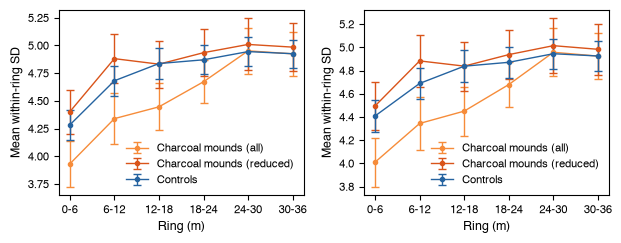

In [77]:
runs = {"Charcoal mounds (all)": out_all, "Charcoal mounds (reduced)": out_red, "Controls": out_ctrl}

runs_w = {"Charcoal mounds (all)": out_all_w, "Charcoal mounds (reduced)": out_red_w, "Controls": out_ctrl_w}

GROUP_COLS = {"Charcoal mounds (all)":     COLSCHEME["ember"][1],
              "Charcoal mounds (reduced)": COLSCHEME["ember"][2],
              "Controls":                  COLSCHEME["smoke"][2]}

fig, ax = plt.subplots(1,2, figsize=(6.3, 2.5))
for label, out in runs.items():
    sd = ring_sd(out)
    mean = sd.mean()                       # average SD per ring over all kilns
    se = sd.std() / np.sqrt(sd.count())    # standard error of that average
    ax[0].errorbar(mean.index, mean, yerr=se, marker="o", capsize=3, markersize=3, lw=1, label=label, color=GROUP_COLS[label])
ax[0].set_xlabel("Ring (m)")
ax[0].set_ylabel("Mean within-ring SD")
ax[0].legend(frameon=False)
for label, out in runs_w.items():
    sd = ring_sd(out)
    mean = sd.mean()                       # average SD per ring over all kilns
    se = sd.std() / np.sqrt(sd.count())    # standard error of that average
    ax[1].errorbar(mean.index, mean, yerr=se, marker="o", capsize=3, markersize=3, lw=1, label=label, color=GROUP_COLS[label])
ax[1].set_xlabel("Ring (m)")
ax[1].set_ylabel("Mean within-ring SD")
ax[1].legend(frameon=False)
plt.tight_layout()
save_fig("sd_comparison_weighted_unweighted", fig=fig)


Text(0, 0.5, 'Ring SD (m)')

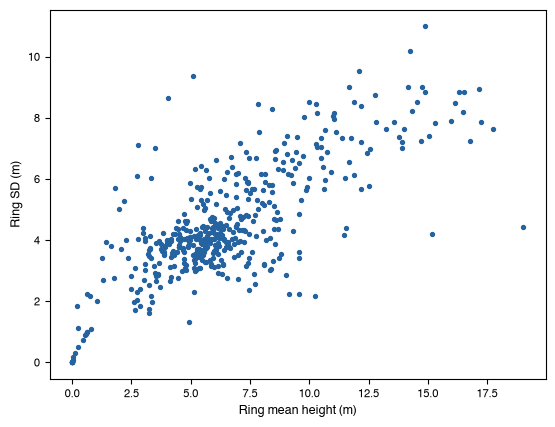

In [81]:
sd = ring_sd(out_all)
mean = out_all["rings"][[c for c in out_all["rings"].columns if c.startswith("mean_")]]
plt.scatter(mean.to_numpy().ravel(), sd.to_numpy().ravel(), s=8)
plt.xlabel("Ring mean height (m)"); plt.ylabel("Ring SD (m)")

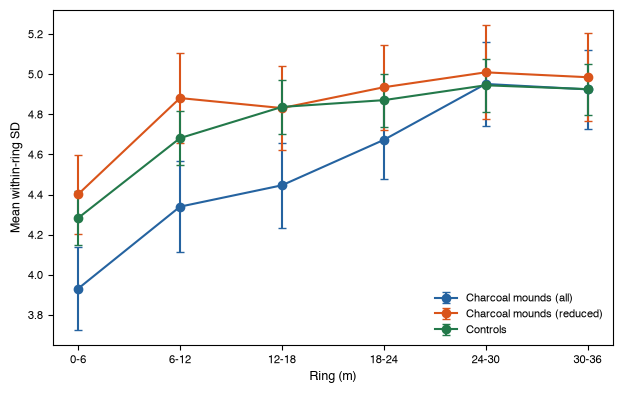

In [79]:
runs = {"Charcoal mounds (all)": out_all, "Charcoal mounds (reduced)": out_red, "Controls": out_ctrl}

fig, ax = plt.subplots(figsize=(6.3, 4))
for label, out in runs.items():
    sd = ring_sd(out)
    mean = sd.mean()                       # average SD per ring over all kilns
    se = sd.std() / np.sqrt(sd.count())    # standard error of that average
    ax.errorbar(mean.index, mean, yerr=se, marker="o", capsize=3, label=label)

ax.set_xlabel("Ring (m)")
ax.set_ylabel("Mean within-ring SD")
ax.legend(frameon=False)
plt.tight_layout()

            n kilns  mean SD diff     SE  Wilcoxon p  mean height diff
ring_index                                                            
0-6              58        -0.032  0.174       0.725            -0.472
6-12             58        -0.128  0.148       0.343            -0.096
12-18            58         0.096  0.136       0.874             0.097
18-24            58        -0.013  0.128       0.498            -0.164
24-30            58         0.034  0.124       0.917            -0.035
30-36            58         0.028  0.113       0.904            -0.295


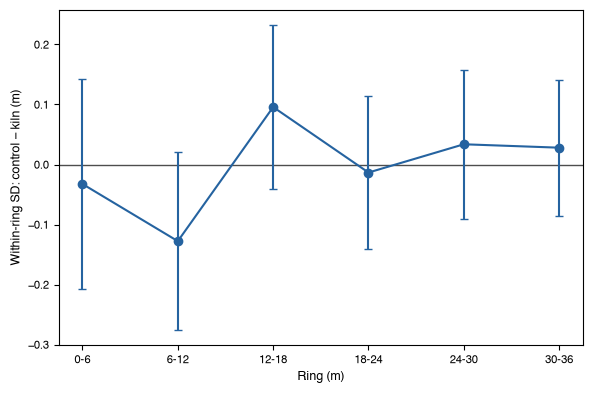

In [82]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

CTRL_ID  = "ID_PAROLINI"   # unique ID per control (the id_column used for the controls run)
KILN_REF = "kiln_id"      # column in controls_2056.gpkg naming the kiln each control belongs to

# Which kiln each control belongs to
ctrl = gpd.read_file("controls_2056.gpkg")
pair = ctrl.set_index(ctrl[CTRL_ID].astype(str))[KILN_REF].astype(str)

def per_kiln(table, is_control):
    """Index as strings; for controls, average all controls of the same kiln."""
    table = table.copy()
    table.index = table.index.astype(str)
    if is_control:
        table = table.groupby(pair.reindex(table.index).to_numpy()).mean()
    return table

def mean_table(out):
    r = out["rings"]
    cols = [c for c in r.columns if c.startswith("mean_")]
    t = r[cols]
    t.columns = ring_sd(out).columns   # same ring labels as the SD table
    return t

# Control minus its kiln, one value per kiln and ring
sd_kiln = per_kiln(ring_sd(out_red), is_control=False)
sd_ctrl = per_kiln(ring_sd(out_ctrl), is_control=True)
kilns = sd_kiln.index.intersection(sd_ctrl.index)
sd_diff = sd_ctrl.loc[kilns] - sd_kiln.loc[kilns]

# Same for mean height, to check the pairs sit in similar forest
h_diff = (per_kiln(mean_table(out_ctrl), True).loc[kilns]
          - per_kiln(mean_table(out_red), False).loc[kilns])

# Overview per ring
summary = pd.DataFrame({
    "n kilns":          sd_diff.count(),
    "mean SD diff":     sd_diff.mean(),
    "SE":               sd_diff.std() / np.sqrt(sd_diff.count()),
    "Wilcoxon p":       [wilcoxon(sd_diff[c].dropna()).pvalue for c in sd_diff],
    "mean height diff": h_diff.mean(),
})
print(summary.round(3))

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
ax.axhline(0, color="0.3", lw=1)
ax.errorbar(summary.index, summary["mean SD diff"], yerr=summary["SE"],
            marker="o", capsize=3, color="#2563A0")
ax.set_xlabel("Ring (m)")
ax.set_ylabel("Within-ring SD: control − kiln (m)")
plt.tight_layout()

### Paired comparison of within-ring variability

Within-ring SD increases with mean canopy height (Figure X), so pooling absolute SDs across sites would mix differences in forest structure with differences in canopy height. Instead, each kiln was compared with its own control points, which lie in similar forest and terrain nearby.

For every site and ring, the SD of the normalised surface heights was calculated from all valid ray samples within the ring (see above). For each kiln, the SDs of its control points were averaged, and the kiln's SD was subtracted from this average. This gives one paired difference per kiln and ring, so that kilns with more control points do not carry more weight. Positive values mean the vegetation around the controls is more variable than around the kiln.

The paired differences were averaged over all kilns, and their uncertainty is shown as ±1 standard error. A Wilcoxon signed-rank test was used to test whether the differences in each ring are centred on zero, as it does not assume normally distributed differences. To check that the pairing removed the effect of canopy height, the mean height differences between controls and kilns were calculated in the same way.

### Results

In all six rings, the controls show a slightly higher within-ring SD than their kilns, with mean differences between 0.05 and 0.14 m. The difference is largest in the innermost ring (0–6 m) and smallest in the outermost ring (30–36 m), but there is no clear trend with distance from the kiln. The standard errors (about ±0.1 m) are of the same size as the differences, and the error bars include zero in four of the six rings (Wilcoxon p = [values]).

Compared with typical within-ring SDs of 3–8 m, these differences amount to only a few percent. Vegetation structure around charcoal kilns is therefore not measurably more or less heterogeneous than in comparable forest nearby, at least at the resolution of this analysis. The mean canopy height differed by [value] m between controls and kilns, so [the pairing removed / did not fully remove] the scale effect of canopy height.

In [83]:
from scipy.stats import wilcoxon, ttest_1samp, friedmanchisquare

def paired_tests(diff, raw=None, unit="m"):
    """Tests on paired differences (control − kiln): one row per kiln, one column per ring.
    raw: optional {label: table} of the raw values, to test the change across rings."""
    rows = []
    for c in diff:
        x = diff[c].dropna()
        ci = ttest_1samp(x, 0).confidence_interval(0.95)
        rows.append({"ring": c, "n": len(x), "mean diff": x.mean(),
                     "95% CI low": ci.low, "95% CI high": ci.high,
                     "Wilcoxon p": wilcoxon(x).pvalue})
    tests = pd.DataFrame(rows).set_index("ring")

    # Holm correction for the per-ring tests
    p = tests["Wilcoxon p"].to_numpy()
    order = np.argsort(p)
    adj = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    tests.loc[tests.index[order], "Holm p"] = adj
    print(tests.round(3))

    # Overall: each kiln's difference averaged over all rings, one test
    overall = diff.mean(axis=1).dropna()
    ci = ttest_1samp(overall, 0).confidence_interval(0.95)
    print(f"\nAll rings together: mean diff = {overall.mean():.3f} {unit} "
          f"(95% CI {ci.low:.3f} to {ci.high:.3f}), "
          f"Wilcoxon p = {wilcoxon(overall).pvalue:.3f} (n = {len(overall)})")

    # Does the paired difference change across rings?
    d = diff.dropna()
    print(f"Paired difference across rings: Friedman p = "
          f"{friedmanchisquare(*[d[c] for c in d]).pvalue:.3f} (n = {len(d)})")

    # Do the raw values change across rings? (method artefact for the SD)
    for label, t in (raw or {}).items():
        t = t.dropna()
        print(f"Raw values across rings, {label}: Friedman p = "
              f"{friedmanchisquare(*[t[c] for c in t]).pvalue:.4f} (n = {len(t)})")
    return tests

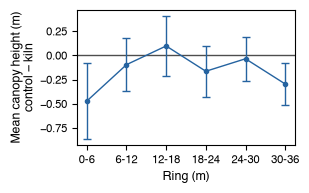

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


=== Mean canopy height (m) ===
        n  mean diff  95% CI low  95% CI high  Wilcoxon p  Holm p
ring                                                             
0-6    58     -0.472      -1.257        0.313       0.223     1.0
6-12   58     -0.096      -0.651        0.460       0.754     1.0
12-18  58      0.097      -0.520        0.715       0.725     1.0
18-24  58     -0.164      -0.697        0.369       0.730     1.0
24-30  58     -0.035      -0.486        0.416       0.843     1.0
30-36  58     -0.295      -0.722        0.131       0.347     1.0

All rings together: mean diff = -0.161 m (95% CI -0.616 to 0.294), Wilcoxon p = 0.335 (n = 58)
Paired difference across rings: Friedman p = 0.430 (n = 58)
Raw values across rings, mounds: Friedman p = 0.2096 (n = 60)
Raw values across rings, controls: Friedman p = 0.6888 (n = 170)



1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


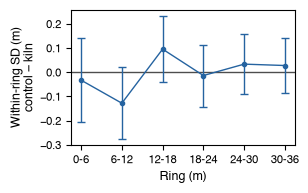

1 extra bytes in post.stringData array


=== Within-ring SD (m) ===
        n  mean diff  95% CI low  95% CI high  Wilcoxon p  Holm p
ring                                                             
0-6    58     -0.032      -0.381        0.316       0.725     1.0
6-12   58     -0.128      -0.424        0.168       0.343     1.0
12-18  58      0.096      -0.177        0.369       0.874     1.0
18-24  58     -0.013      -0.270        0.243       0.498     1.0
24-30  58      0.034      -0.215        0.282       0.917     1.0
30-36  58      0.028      -0.199        0.255       0.904     1.0

All rings together: mean diff = -0.003 m (95% CI -0.234 to 0.228), Wilcoxon p = 0.607 (n = 58)
Paired difference across rings: Friedman p = 0.460 (n = 58)
Raw values across rings, mounds: Friedman p = 0.0050 (n = 60)
Raw values across rings, controls: Friedman p = 0.0000 (n = 170)



'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


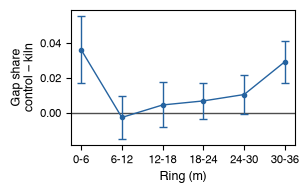

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


=== Gap share ===
        n  mean diff  95% CI low  95% CI high  Wilcoxon p  Holm p
ring                                                             
0-6    58      0.036      -0.002        0.075       0.044   0.221
6-12   58     -0.003      -0.027        0.022       0.874   1.000
12-18  58      0.004      -0.021        0.030       0.432   1.000
18-24  58      0.007      -0.014        0.028       0.418   1.000
24-30  58      0.010      -0.012        0.033       0.340   1.000
30-36  58      0.029       0.005        0.054       0.020   0.121

All rings together: mean diff = 0.014  (95% CI -0.000 to 0.028), Wilcoxon p = 0.043 (n = 58)
Paired difference across rings: Friedman p = 0.260 (n = 58)
Raw values across rings, mounds: Friedman p = 0.0130 (n = 60)
Raw values across rings, controls: Friedman p = 0.2346 (n = 170)



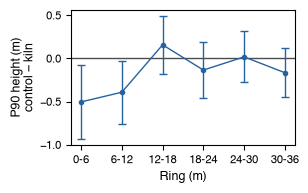

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


=== P90 height (m) ===
        n  mean diff  95% CI low  95% CI high  Wilcoxon p  Holm p
ring                                                             
0-6    58     -0.505      -1.364        0.355       0.206     1.0
6-12   58     -0.392      -1.124        0.340       0.214     1.0
12-18  58      0.157      -0.508        0.823       0.780     1.0
18-24  58     -0.135      -0.784        0.514       0.307     1.0
24-30  58      0.017      -0.574        0.609       0.742     1.0
30-36  58     -0.166      -0.736        0.403       0.707     1.0

All rings together: mean diff = -0.171 m (95% CI -0.744 to 0.402), Wilcoxon p = 0.320 (n = 58)
Paired difference across rings: Friedman p = 0.051 (n = 58)
Raw values across rings, mounds: Friedman p = 0.2351 (n = 60)
Raw values across rings, controls: Friedman p = 0.0000 (n = 170)



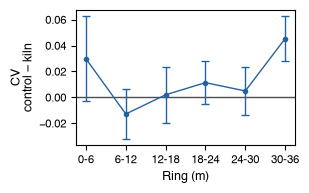

=== CV ===
        n  mean diff  95% CI low  95% CI high  Wilcoxon p  Holm p
ring                                                             
0-6    58      0.030      -0.036        0.095       0.253   1.000
6-12   58     -0.013      -0.051        0.026       0.725   1.000
12-18  58      0.002      -0.041        0.045       0.548   1.000
18-24  58      0.011      -0.022        0.045       0.343   1.000
24-30  58      0.005      -0.032        0.042       0.713   1.000
30-36  58      0.045       0.011        0.080       0.009   0.051

All rings together: mean diff = 0.013  (95% CI -0.012 to 0.039), Wilcoxon p = 0.182 (n = 58)
Paired difference across rings: Friedman p = 0.476 (n = 58)
Raw values across rings, mounds: Friedman p = 0.0055 (n = 60)
Raw values across rings, controls: Friedman p = 0.0000 (n = 168)



1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


In [85]:
def paired_diff(stat):
    """Control minus its kiln, one row per kiln, one column per ring."""
    k = per_kiln(ring_stat(out_red, stat), is_control=False)
    c = per_kiln(ring_stat(out_ctrl, stat), is_control=True)
    ids = k.index.intersection(c.index)
    return c.loc[ids] - k.loc[ids]

results = {}
for name, stat in STATS.items():
    diff = paired_diff(stat)

    fig, ax = plt.subplots(figsize=(3.15, 2))
    ax.axhline(0, color="0.3", lw=1)
    ax.errorbar(diff.columns, diff.mean(), yerr=diff.std() / np.sqrt(diff.count()),
                marker="o", markersize=3, lw=1, capsize=3, color="#2563A0")
    ax.set_xlabel("Ring (m)")
    ax.set_ylabel(f"{name}\ncontrol − kiln")
    plt.tight_layout()
    plt.show()

    print(f"=== {name} ===")
    results[name] = paired_tests(diff, raw={"mounds": ring_stat(out_red, stat),
                                            "controls": ring_stat(out_ctrl, stat)},
                                            unit="" if name in ("Gap share", "CV") else "m")
    print()
    save_fig(f"{name}_statistic", fig=fig)

To test whether the vegetation around charcoal mounds differs in heterogeneity from comparable forest nearby, the paired differences in within-ring SD (control minus mound) were tested against zero for each ring with a Wilcoxon signed-rank test, and the p-values were corrected for multiple testing with the Holm method. The comparison included the 58 mounds for which at least one control point could be placed. None of the six rings showed a significant difference (uncorrected p ≥ 0.34, Holm-corrected p = 1.0), and the mean differences ranged from −0.13 to 0.10 m. Averaged over all rings, the difference was −0.003 m (95 % CI [low] to [high] m, Wilcoxon p = 0.61). A Friedman test showed no change in the paired differences across rings (p = [p]), so there is no indication that any effect of the mounds depends on distance. In contrast, the raw within-ring SD increased significantly from the inner to the outer rings for both mounds (Friedman p = [p]) and controls (p = [p]). This increase therefore reflects the sampling geometry rather than the mounds: smaller rings sample points closer together, which are more strongly correlated in height. The paired design removes this effect from the comparison. Overall, we found no evidence that charcoal mounds affect the heterogeneity of the surrounding canopy; given the confidence intervals, any such effect is smaller than about 0.4 m, or 9 % of the typical within-ring SD.

mean height, P90, SD and CV show no differences between mounds and controls. The gap share differs marginally (p = 0.043), but not after correction for testing several measures. The differences that remain are small, at most about 0.5 m in height or a few percentage points in gap share. At the resolution of this analysis, there’s no evidence that the charcoal mounds still affect the canopy.